### Import Modules

In [43]:
import os
from pathlib import Path
import pandas as pd 
import numpy as np
from scipy.stats import zscore

try:
    import utils.process_analysis
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

#### 1. CONFIGURATION

In [12]:
DATA_DIR = "../data/02_processed_combined_data"

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
N_SAMPLES = 5000
current_dir = os.getcwd()
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))

In [44]:
pc_subjs = utils.process_analysis.get_subjects_by_condition(CONDITIONS_FILE, target_condition='PC', exclude_prior_exposure=False) 
results = utils.process_analysis.load_filtered_physiological_data(DATA_DIR, pc_subjs)
results.keys()



# axis=0 (default) standardizes each column (subject) independently
# Then we extract the values and transpose them
gaze_x_matrix_zscored = zscore(results['Gaze_X'], axis=0).T
gaze_y_matrix_zscored = zscore(results['Gaze_Y'], axis=0).T
pupil_mean_matrix_zscored = zscore(results['Pupil_Mean'], axis=0).T
heart_rate_matrix_zscored = zscore(results['Heart_Rate'], axis=0).T
gsr_matrix_zscored = zscore(results['GSR'], axis=0).T

Scanning 193 files against 99 subject IDs...
Successfully loaded 96 valid subjects.


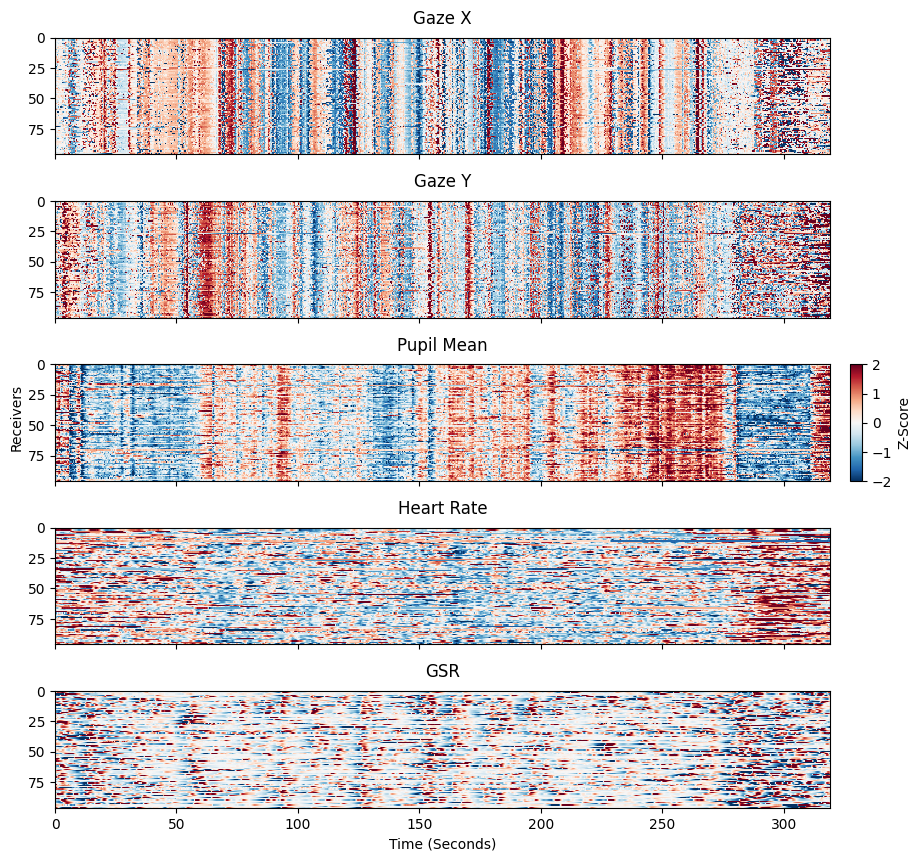

In [86]:
# ==========================================
# 4. PLOTTING
# ==========================================
VMIN, VMAX = -2.0, 2.0 
MAX_TIME_SEC = 319  # <-- Set your max time in seconds here

fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True, gridspec_kw={'height_ratios': [1, 1, 1, 1, 1]})
CMAP = 'RdBu_r'

# Update the 'extent' parameter in all 5 subplots: [0, MAX_TIME_SEC, bottom, top]
im0 = axes[0].imshow(gaze_x_matrix_zscored, aspect='auto', cmap=CMAP, vmin=VMIN, vmax=VMAX,
                     extent=[0, MAX_TIME_SEC, real_matrix.shape[0], 0], interpolation='none')
axes[0].set_title("Gaze X", fontsize=12, pad=10)

im1 = axes[1].imshow(gaze_y_matrix_zscored, aspect='auto', cmap=CMAP, vmin=VMIN, vmax=VMAX,
                     extent=[0, MAX_TIME_SEC, real_matrix.shape[0], 0], interpolation='none')
axes[1].set_title("Gaze Y", fontsize=12, pad=10)

im2 = axes[2].imshow(pupil_mean_matrix_zscored, aspect='auto', cmap=CMAP, vmin=VMIN, vmax=VMAX,
                     extent=[0, MAX_TIME_SEC, real_matrix.shape[0], 0], interpolation='none')
axes[2].set_title("Pupil Mean", fontsize=12, pad=10)

im3 = axes[3].imshow(heart_rate_matrix_zscored, aspect='auto', cmap=CMAP, vmin=VMIN, vmax=VMAX,
                     extent=[0, MAX_TIME_SEC, real_matrix.shape[0], 0], interpolation='none')
axes[3].set_title("Heart Rate", fontsize=12, pad=10)

im4 = axes[4].imshow(gsr_matrix_zscored, aspect='auto', cmap=CMAP, vmin=VMIN, vmax=VMAX,
                     extent=[0, MAX_TIME_SEC, real_matrix.shape[0], 0], interpolation='none')
axes[4].set_title("GSR", fontsize=12, pad=10)

# 1. Center a master Y-axis label for the whole figure
fig.supylabel("Receivers", fontsize=10, x=0.08)

# 2. Add X-axis label to the bottom subplot
axes[4].set_xlabel("Time (Seconds)", fontsize=10)

# Apply layout adjustments FIRST so the subplots settle into their final positions
plt.subplots_adjust(right=0.9, hspace=0.4)

# 3. Center the colorbar exactly on subplot 3 
pos = axes[2].get_position()
cbar_ax = fig.add_axes([0.92, pos.y0, 0.012, pos.height]) 
fig.colorbar(im2, cax=cbar_ax, label="Z-Score")

plt.savefig("audience_alignment_figure.png", dpi=300, bbox_inches='tight')

plt.show()

In [87]:
os.getcwd()

'/Users/schmaelz/Documents/01_GITHUB/nomcomm/GITHUB_PAPERS_WORKING/PC_HJ/scripts'